<a href="https://colab.research.google.com/github/dwesizv/Colab/blob/main/pr%C3%A1ctica_1_teachable_machine_resuelta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

https://teachablemachine.withgoogle.com/

Se debe crear un proyecto de tipo imagen con imágenes estándar y entrenar al menos dos categorías de imágenes.

Una vez recogidas las dos muestras de entrenamiento, se debe preparar el modelo.

Una vez preparado el modelo se debe exportar usando la opción Tensorflow.js.

La ejecución del código que se ofrece en Javascript permite probar el modelo en local.

La estructura de carpetas de la aplicación en local debe ser la siguiente:


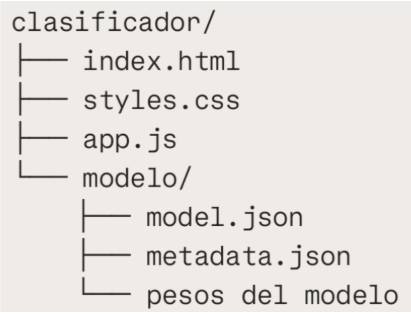

Una vez que funcione el modelo, se deben realizar una serie de mejoras:

* mejorar el diseño de la página
* hacer la página responsive
* poner un botón de inicio y otro de parada
* mostrar un mensaje personalizado de salida
* dejar establecer un valor mínimo a partir del cual se considera que hay una coincidencia
* guardar un histórico de resultados y mostrarlo
* permitir que se suba una imagen para calificarla

Se debe entregar una memoria hecha con Colab en la que se explique textualmente y con capturas todo el proceso.

Tiempo: de 2 a 3 horas de clase.

# **Guarda y exporta**

Guarda el proyecto. Exporta también el modelo tanto para Tensorflow.js como Tensorflow, ya que necesitarás utilizarlo de nuevo en una práctica más adelante.

# Resolución de la práctica. Paso a paso.

Implemento una aplicación en html y javascript con la que puedo subir un archivo y visualizarlo.

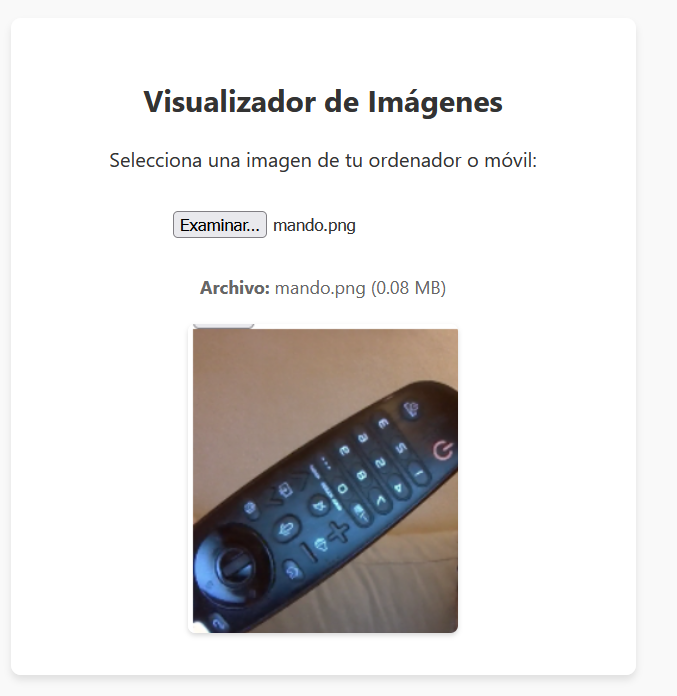

El código fuente de esta página queda del siguiente modo:



```
<div>
    <input type="file" id="selector-imagen" accept="image/*">
    <img id="vista-previa" alt="imagen subida">
</div>

<script>
    const selectorImagen = document.getElementById('selector-imagen');
    const vistaPrevia = document.getElementById('vista-previa');

    selectorImagen.addEventListener('change', function(evento) {
        const archivos = evento.target.files;
        if (archivos.length === 0) {
            return;
        }
        const archivo = archivos[0];
        const lector = new FileReader();
        lector.onload = function(e) {
            vistaPrevia.src = e.target.result;
        };
        lector.readAsDataURL(archivo);
    });
</script>

```


Implemento una aplicación en html y javascript con la que puedo iniciar y detener la webcam.

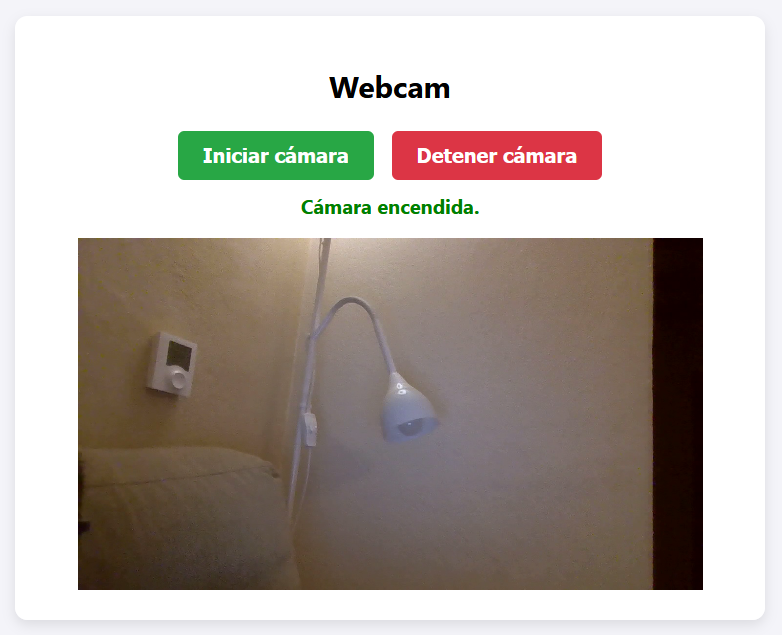

El código fuente de esta página queda de este modo:



```
<div>
    <video id="webcam" autoplay playsinline></video>
</div>
<script>
    const video = document.getElementById('webcam');
    async function encenderCamara() {
        if (navigator.mediaDevices && navigator.mediaDevices.getUserMedia) {
            try {
                const stream = await navigator.mediaDevices.getUserMedia({
                    video: { width: 1280, height: 720 },
                    audio: false
                });
                video.srcObject = stream;
            } catch (error) {
                console.error(error);
            }
        } else {
            console.error('error');
        }
    }
    window.onload = encenderCamara;
</script>
```



Ahora la añado a la aplicación con la que subo las imágenes el uso del modelo de teachable machine.

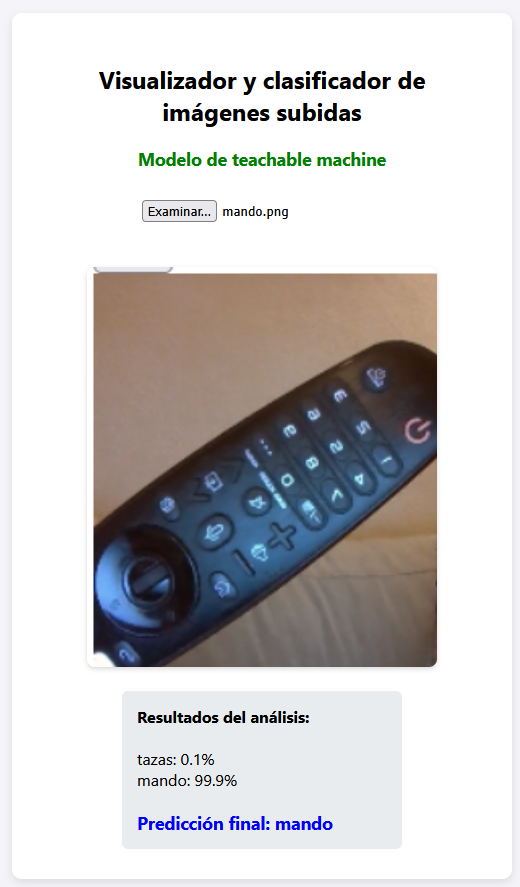

El código fuente de esta página queda del siguiente modo:


Carga de scripts.

```
<script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@latest/dist/tf.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@latest/dist/teachablemachine-image.min.js"></script>
```

Parte HTML.

```
<div>
    <input type="file" id="selector-imagen" accept="image/*">
    <img id="vista-previa" alt="imagen subida">
    <div id="resultado-div"></div>
</div>
```

Parte javascript.

```
const selectorImagen = document.getElementById('selector-imagen');
const vistaPrevia = document.getElementById('vista-previa');
const resultadoDiv = document.getElementById('resultado-div');

const URL_MODELO = "./modelo/";
let model, maxPredictions;
```

Nada más cargarse la página se obtiene el modelo de Teachable Machine.

```
async function cargarModelo() {
    try {
        const modelURL = URL_MODELO + "model.json";
        const metadataURL = URL_MODELO + "metadata.json";
        model = await tmImage.load(modelURL, metadataURL);
        maxPredictions = model.getTotalClasses();
    } catch (error) {
        console.error(error);
    }
}
window.onload = cargarModelo;
```



Cuando se produzca la selección de una imagen, la imagen se lee y se visualiza. Se define el evento, que al terminar de cargar la imagen, lanza la predicción del tipo de imagen.

```
selectorImagen.addEventListener('change', function(evento) {
    const archivos = evento.target.files;
    if (archivos.length === 0) {
        return;
    }
    const archivo = archivos[0];
    const lector = new FileReader();
    lector.onload = function(e) {
        vistaPrevia.src = e.target.result;
        vistaPrevia.onload = async function() {
            await ejecutarPrediccion();
        }
    };
    lector.readAsDataURL(archivo);
});
```



Se obtiene la predicción del modelo, se extrae la clase con mayor procentaje y se muestra el resultado.

```
async function ejecutarPrediccion() {
    const prediction = await model.predict(vistaPrevia);
    let mejorPrediccion = { className: "", probability: 0 };
    for (let i = 0; i < maxPredictions; i++) {
        if (prediction[i].probability > mejorPrediccion.probability) {
            mejorPrediccion = prediction[i];
        }
    }
    let htmlContenido = `<br>Predicción: ${mejorPrediccion.className} ${mejorPrediccion.probability}</span>`;
    resultadoDiv.innerHTML = htmlContenido;
}
```

